# 03a — StreetCLIP Dual-Head ViT (Linear Probe & Fine-Tuning)

Trains and evaluates **`geolocal/StreetCLIP`** (`ViT-L/14@336px`) on the Timeguessr AI task using the **`semantic_medium`** discretization (`1,249` country-pure tiles) and exact scoring formulas from `formulas.txt`.

**Two-Stage Pipeline:**
1. **Stage 1 — Linear Probe (`outputs/models/streetclip_linear_probe/`):** Extract & cache frozen StreetCLIP embeddings once (reusable by Notebook 02 FAISS), then train dual MLP heads with Gaussian year smoothing (`sigma=2.0`) and GPU geodesic distance soft labels (`tau=75 km`).
2. **Stage 2 — Fine-Tuning (`outputs/models/streetclip_finetune/`):** Warm-start the dual heads from Stage 1, unfreeze the **last 6 ViT blocks**, and fine-tune end-to-end in `bfloat16` with gradient checkpointing and geolocation-safe augmentations (no horizontal flip).

## 1. Setup & Configuration

In [4]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from timeguessr_ai import (
    clear_device_cache,
    extract_and_cache_embeddings,
    format_device_info,
    get_default_device,
    load_cached_embeddings,
    load_dataset_and_tiles,
    train_finetune,
    train_linear_probe,
)

DEVICE = str(get_default_device())
print(f"Project root: {PROJECT_ROOT}")
print(f"Device:       {format_device_info(DEVICE)}")

Project root: d:\VSCodeProjects\CS441
Device:       cuda (NVIDIA GeForce RTX 4070 SUPER)


In [5]:
CFG = {
    "model_id": "geolocal/StreetCLIP",
    "model_label": "StreetCLIP (ViT-L/14@336)",
    "tile_scheme": "semantic_medium",
    "sigma_year": 2.0,
    "tau_geo_km": 135.0,
    "country_alpha": 0.7,
    "w_time": 1.0,
    "dropout": 0.2,
    "seed": 42,
    # Stage 1: Embedding extraction & Linear Probe
    "use_cached_embeddings": True,  # Load & sanity-check cached .npy embeddings; False = re-extract
    "extract_batch_size": 64,
    "lp_epochs": 25,
    "lp_batch_size": 512,
    "lp_lr": 1e-3,
    # Stage 2: Fine-tuning (tuned for 12 GB VRAM RTX 4070 SUPER)
    "unfreeze_last_n": 6,
    "ft_epochs": 5,
    "ft_batch_size": 16,
    "ft_grad_accum": 4,  # effective batch size = 64
    "ft_backbone_lr": 2e-5,
    "ft_head_lr": 3e-4,
    "num_workers": 0,    # 0 is safest on Windows Jupyter; increase to 2-4 on Linux
}

LP_OUT_DIR = PROJECT_ROOT / "outputs" / "models" / "streetclip_linear_probe"
FT_OUT_DIR = PROJECT_ROOT / "outputs" / "models" / "streetclip_finetune"

splits, cells_df, tile_col = load_dataset_and_tiles(PROJECT_ROOT, tile_scheme=CFG["tile_scheme"])
print(f"Tiles ({CFG['tile_scheme']}): {len(cells_df):,}")
for k, v in splits.items():
    print(f"  {k:16s}: {len(v):7,d} images")

Tiles (semantic_medium): 841
  train           :  87,056 images
  val             :   9,584 images
  test_timeguessr :   1,600 images


## 2. Stage 1 — Extract Frozen Embeddings & Train Linear Probe

Embeddings are cached to `data/embeddings/geolocal__StreetCLIP/` so re-running or tuning head hyperparameters takes seconds, and Notebook 02 (FAISS KNN) can reuse the exact same vectors.

In [6]:
if CFG["use_cached_embeddings"]:
    embeddings = load_cached_embeddings(
        model_id=CFG["model_id"],
        splits=splits,
        project_root=PROJECT_ROOT,
    )
else:
    embeddings = extract_and_cache_embeddings(
        model_id=CFG["model_id"],
        splits=splits,
        project_root=PROJECT_ROOT,
        batch_size=CFG["extract_batch_size"],
        num_workers=CFG["num_workers"],
        device=DEVICE,
        force=True,
    )

[CACHE OK] Loaded & verified cached embeddings for geolocal/StreetCLIP from d:\VSCodeProjects\CS441\data\embeddings\geolocal__StreetCLIP (train=(87056, 1024), val=(9584, 1024), test_timeguessr=(1600, 1024))
  Exact image_path SHA-256 manifest verified for: ['train', 'val', 'test_timeguessr']


In [11]:
lp_result = train_linear_probe(
    embeddings=embeddings,
    splits=splits,
    cells_df=cells_df,
    output_dir=LP_OUT_DIR,
    run_config={**CFG, "stage": "linear_probe", "run_name": "streetclip_linear_probe"},
    epochs=CFG["lp_epochs"],
    batch_size=CFG["lp_batch_size"],
    lr=CFG["lp_lr"],
    sigma_year=CFG["sigma_year"],
    tau_geo_km=CFG["tau_geo_km"],
    w_time=CFG["w_time"],
    dropout=CFG["dropout"],
    country_alpha=CFG["country_alpha"],
    device=DEVICE,
    seed=CFG["seed"],
)

print("\n=== Stage 1 (StreetCLIP Linear Probe) — Held-Out Timeguessr Test ===")
display(pd.DataFrame([lp_result["test_metrics"]]).T.rename(columns={0: "StreetCLIP Linear Probe"}))

Epoch 01/25 ( 2.2s) | loss=6.7315 (s=3.754, t=2.978) | val_total=7912.4 (loc=3543.0, yr=4369.4) | med_km=284.6 | yr_mae=4.25
Epoch 02/25 ( 1.9s) | loss=5.8872 (s=3.147, t=2.740) | val_total=7986.0 (loc=3590.5, yr=4395.5) | med_km=262.6 | yr_mae=4.12
Epoch 03/25 ( 2.3s) | loss=5.6187 (s=2.944, t=2.674) | val_total=8068.3 (loc=3617.2, yr=4451.1) | med_km=248.4 | yr_mae=3.81
Epoch 04/25 ( 1.9s) | loss=5.4401 (s=2.823, t=2.617) | val_total=8103.1 (loc=3644.4, yr=4458.7) | med_km=244.3 | yr_mae=3.76
Epoch 05/25 ( 2.2s) | loss=5.2876 (s=2.713, t=2.575) | val_total=8152.3 (loc=3686.7, yr=4465.6) | med_km=234.7 | yr_mae=3.75
Epoch 06/25 ( 1.9s) | loss=5.1917 (s=2.653, t=2.538) | val_total=8176.6 (loc=3690.0, yr=4486.6) | med_km=230.1 | yr_mae=3.60
Epoch 07/25 ( 2.3s) | loss=5.0933 (s=2.588, t=2.505) | val_total=8195.1 (loc=3697.0, yr=4498.1) | med_km=230.1 | yr_mae=3.56
Epoch 08/25 ( 2.0s) | loss=5.0204 (s=2.541, t=2.480) | val_total=8219.1 (loc=3728.5, yr=4490.6) | med_km=222.6 | yr_mae=3.57


,StreetCLIP Linear Probe
n_samples,1600.00
total_score_mean,7616.56
total_score_median,8099.86
loc_score_mean,3444.98
loc_score_median,3995.34
year_score_mean,4171.58
year_score_median,4552.81
dist_err_median_km,376.89
dist_err_mean_km,1219.42
within_25km_pct,0.62


## 3. Stage 2 — Fine-Tune Last 6 ViT Blocks (Warm-Started from Stage 1)

Loads the best dual MLP heads from Stage 1, unfreezes the final 6 transformer blocks of StreetCLIP, and fine-tunes end-to-end with differential learning rates (`2e-5` backbone / `3e-4` heads), `bfloat16`, and gradient checkpointing.

In [4]:
# Free cached embeddings from RAM before Stage 2 image fine-tuning
if "embeddings" in globals():
    del embeddings
clear_device_cache(DEVICE)

ft_result = train_finetune(
    model_id=CFG["model_id"],
    splits=splits,
    cells_df=cells_df,
    project_root=PROJECT_ROOT,
    output_dir=FT_OUT_DIR,
    run_config={**CFG, "stage": "finetune", "run_name": "streetclip_finetune"},
    warmstart_checkpoint=LP_OUT_DIR / "best_checkpoint.pt",
    unfreeze_last_n=CFG["unfreeze_last_n"],
    epochs=CFG["ft_epochs"],
    batch_size=CFG["ft_batch_size"],
    grad_accum_steps=CFG["ft_grad_accum"],
    backbone_lr=CFG["ft_backbone_lr"],
    head_lr=CFG["ft_head_lr"],
    sigma_year=CFG["sigma_year"],
    tau_geo_km=CFG["tau_geo_km"],
    w_time=CFG["w_time"],
    dropout=CFG["dropout"],
    country_alpha=CFG["country_alpha"],
    num_workers=CFG["num_workers"],
    device=DEVICE,
    seed=CFG["seed"],
    resume=True,
)

print("\n=== Stage 2 (StreetCLIP Fine-Tune) — Held-Out Timeguessr Test ===")
display(pd.DataFrame([ft_result["test_metrics"]]).T.rename(columns={0: "StreetCLIP Fine-Tune"}))

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: geolocal/StreetCLIP
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_pr

Warm-started dual heads from d:\VSCodeProjects\CS441\outputs\models\streetclip_linear_probe\best_checkpoint.pt
Fine-tuning geolocal/StreetCLIP | unfrozen last 6 blocks (75.58M backbone + 2.51M heads) | eff_batch=64


Finetune Ep 1/5:   0%|          | 0/5441 [00:00<?, ?it/s]

d:\VSCodeProjects\CS441\.venv\Lib\site-packages\PIL\Image.py:3593: DecompressionBombWarning: Image size (89822655 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Epoch 01/5 (66.8 min) | loss=5.0749 (s=2.594, t=2.481) | val_total=8173.1 (loc=3657.8, yr=4515.3) | med_km=232.1 | yr_mae=3.46
  [checkpoint] saved epoch 1 -> last_checkpoint.pt (best_val=8173.1)


... (6 outputs left out)

Epoch 04/5 (62.6 min) | loss=4.5130 (s=2.270, t=2.243) | val_total=8376.0 (loc=3790.6, yr=4585.4) | med_km=209.3 | yr_mae=3.05
  [checkpoint] saved epoch 4 -> last_checkpoint.pt (best_val=8376.0)


Finetune Ep 5/5:   0%|          | 0/5441 [00:00<?, ?it/s]

Epoch 05/5 (62.7 min) | loss=4.4535 (s=2.237, t=2.216) | val_total=8386.2 (loc=3796.8, yr=4589.4) | med_km=209.7 | yr_mae=3.03
  [checkpoint] saved epoch 5 -> last_checkpoint.pt (best_val=8386.2)
Saved standardized outputs to d:\VSCodeProjects\CS441\outputs\models\streetclip_finetune

=== Stage 2 (StreetCLIP Fine-Tune) — Held-Out Timeguessr Test ===


,StreetCLIP Fine-Tune
n_samples,1600.00
total_score_mean,7684.62
total_score_median,8167.54
loc_score_mean,3457.40
loc_score_median,4017.92
year_score_mean,4227.22
year_score_median,4576.99
dist_err_median_km,364.99
dist_err_mean_km,1257.65
within_25km_pct,0.75


## 4. Stage 1 Hyperparameter Sweep (Coordinate Sweep on Cached Embeddings)

Sweeps each Stage 1 hyperparameter one-at-a-time around the baseline `CFG` (~50s per run on cached embeddings), then tests a single combined run using the best `val`-selected value for each axis.

- **Selection metric:** `val_total_score` only (never selects on `test_timeguessr`).
- **Isolation:** Writes all sweep artifacts under `outputs/sweeps/streetclip_stage1/` so `LP_OUT_DIR` is untouched.

Running 18 Stage 1 coordinate-sweep configs (~15 min)...

--- [1/18] baseline ---


d:\VSCodeProjects\CS441\src\timeguessr_ai\data.py:218: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  self.year_idx = torch.from_numpy(df["year_idx"].to_numpy(dtype=np.int64))


Epoch 01/25 ( 2.6s) | loss=6.7315 (s=3.754, t=2.978) | val_total=7912.4 (loc=3543.0, yr=4369.4) | med_km=284.6 | yr_mae=4.25
Epoch 02/25 ( 2.1s) | loss=5.8872 (s=3.147, t=2.740) | val_total=7986.0 (loc=3590.5, yr=4395.5) | med_km=262.6 | yr_mae=4.12
Epoch 03/25 ( 2.0s) | loss=5.6187 (s=2.944, t=2.674) | val_total=8068.3 (loc=3617.2, yr=4451.1) | med_km=248.4 | yr_mae=3.81
Epoch 04/25 ( 2.0s) | loss=5.4401 (s=2.823, t=2.617) | val_total=8103.1 (loc=3644.4, yr=4458.7) | med_km=244.3 | yr_mae=3.76
Epoch 05/25 ( 2.0s) | loss=5.2876 (s=2.713, t=2.575) | val_total=8152.3 (loc=3686.7, yr=4465.6) | med_km=234.7 | yr_mae=3.75
Epoch 06/25 ( 2.0s) | loss=5.1917 (s=2.653, t=2.538) | val_total=8176.6 (loc=3690.0, yr=4486.6) | med_km=230.1 | yr_mae=3.60
Epoch 07/25 ( 2.0s) | loss=5.0933 (s=2.588, t=2.505) | val_total=8195.1 (loc=3697.0, yr=4498.1) | med_km=230.1 | yr_mae=3.56
Epoch 08/25 ( 2.0s) | loss=5.0204 (s=2.541, t=2.480) | val_total=8219.1 (loc=3728.5, yr=4490.6) | med_km=222.6 | yr_mae=3.57


,run_name,val_total_score,val_loc_score,val_year_score,val_median_km,val_year_mae
12,dropout=0.35,8310.54,3772.21,4538.32,215.18,3.32
17,lp_lr=0.003,8304.63,3766.11,4538.52,221.89,3.34
13,dropout=0.5,8300.99,3770.97,4530.02,212.75,3.37
3,tau_geo_km=200.0,8300.13,3762.64,4537.49,220.51,3.33
9,country_alpha=0.85,8298.85,3753.22,4545.63,220.43,3.29
4,tau_geo_km=300.0,8296.25,3758.98,4537.27,221.56,3.34
1,tau_geo_km=50.0,8294.10,3756.48,4537.62,218.90,3.33
2,tau_geo_km=100.0,8293.31,3755.65,4537.66,219.85,3.33
14,weight_decay=0.001,8292.12,3754.72,4537.40,219.61,3.34
0,baseline,8291.58,3754.43,4537.15,219.74,3.34


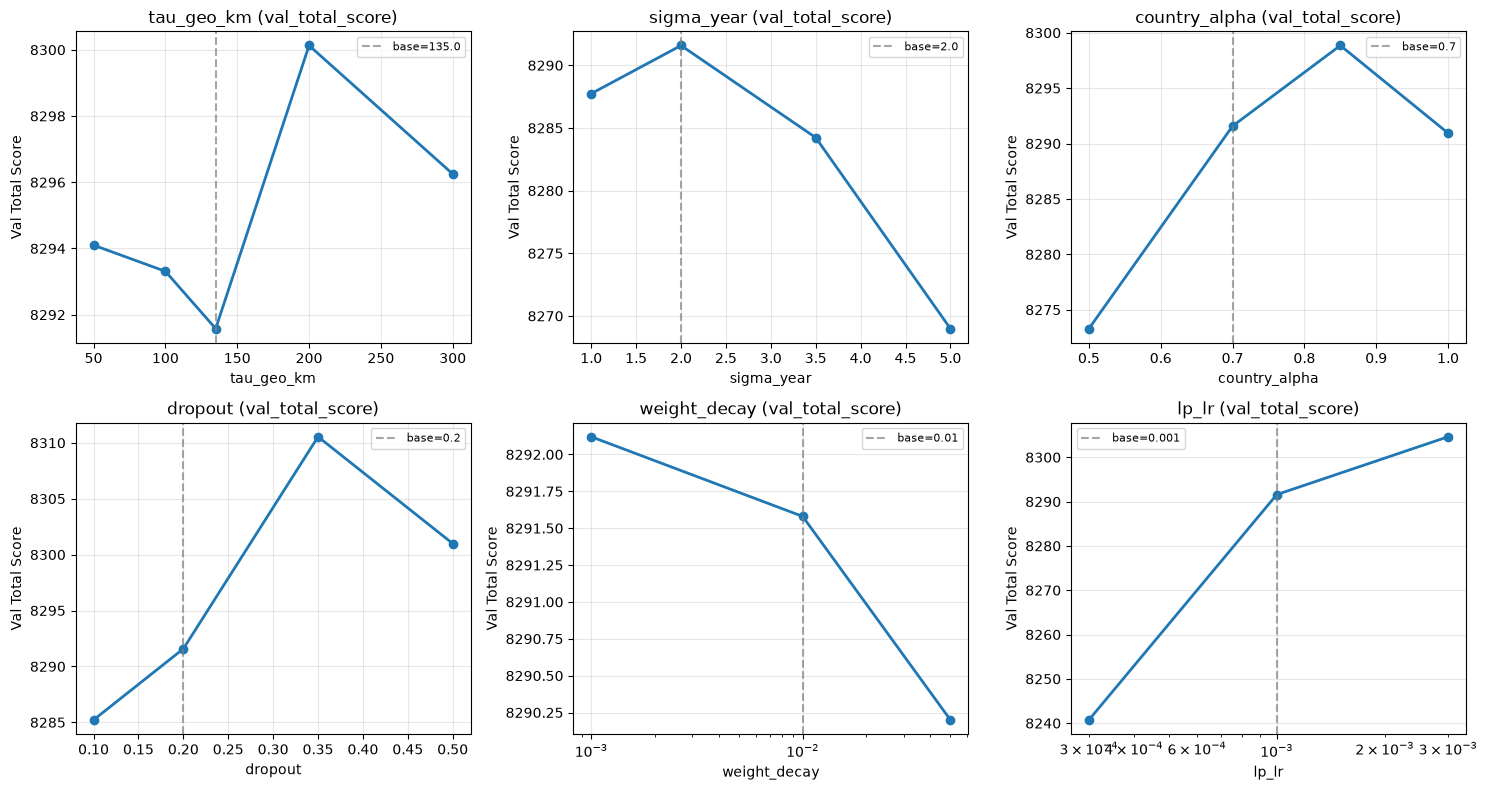

In [7]:
SWEEP_DIR = PROJECT_ROOT / "outputs" / "sweeps" / "streetclip_stage1"
SWEEP_DIR.mkdir(parents=True, exist_ok=True)

# Reload cached embeddings if Stage 2 freed them from RAM
if "embeddings" not in globals():
    embeddings = load_cached_embeddings(
        model_id=CFG["model_id"],
        splits=splits,
        project_root=PROJECT_ROOT,
    )

BASE_LP = {
    "tau_geo_km": CFG["tau_geo_km"],
    "sigma_year": CFG["sigma_year"],
    "country_alpha": CFG["country_alpha"],
    "dropout": CFG["dropout"],
    "weight_decay": CFG.get("weight_decay", 1e-2),
    "lp_lr": CFG["lp_lr"],
    "lp_epochs": CFG["lp_epochs"],
}

SWEEP_GRID = {
    "tau_geo_km": [50.0, 100.0, 135.0, 200.0, 300.0],
    "sigma_year": [1.0, 2.0, 3.5, 5.0],
    "country_alpha": [0.5, 0.7, 0.85, 1.0],
    "dropout": [0.1, 0.2, 0.35, 0.5],
    "weight_decay": [1e-3, 1e-2, 5e-2],
    "lp_lr": [3e-4, 1e-3, 3e-3],
}

# Build deduplicated run list: baseline first, then 1D perturbations
sweep_runs = [("baseline", None, None, dict(BASE_LP))]
for param, values in SWEEP_GRID.items():
    for val in values:
        if val == BASE_LP[param]:
            continue
        run_params = {**BASE_LP, param: val}
        sweep_runs.append((f"{param}={val}", param, val, run_params))

print(f"Running {len(sweep_runs)} Stage 1 coordinate-sweep configs (~{len(sweep_runs) * 0.85:.0f} min)...")

sweep_rows = []
for idx, (run_name, swept_param, swept_val, p) in enumerate(sweep_runs, start=1):
    print(f"\n--- [{idx}/{len(sweep_runs)}] {run_name} ---")
    out_dir = SWEEP_DIR / run_name.replace("=", "_").replace(".", "p")
    res = train_linear_probe(
        embeddings=embeddings,
        splits=splits,
        cells_df=cells_df,
        output_dir=out_dir,
        run_config={**CFG, **p, "stage": "linear_probe_sweep", "run_name": run_name},
        epochs=p["lp_epochs"],
        batch_size=CFG["lp_batch_size"],
        lr=p["lp_lr"],
        weight_decay=p["weight_decay"],
        sigma_year=p["sigma_year"],
        tau_geo_km=p["tau_geo_km"],
        w_time=CFG["w_time"],
        dropout=p["dropout"],
        country_alpha=p["country_alpha"],
        device=DEVICE,
        seed=CFG["seed"],
    )
    vm = res["val_metrics"]
    sweep_rows.append(
        {
            "run_name": run_name,
            "swept_param": swept_param or "baseline",
            "swept_val": swept_val,
            **p,
            "val_total_score": vm["total_score_mean"],
            "val_loc_score": vm["loc_score_mean"],
            "val_year_score": vm["year_score_mean"],
            "val_median_km": vm["dist_err_median_km"],
            "val_year_mae": vm["year_mae"],
            "val_country_acc": vm.get("country_acc_pct", np.nan),
        }
    )

sweep_df = pd.DataFrame(sweep_rows)
sweep_csv = SWEEP_DIR / "sweep_results.csv"
sweep_df.to_csv(sweep_csv, index=False)
print(f"\nSaved sweep results to {sweep_csv}")
display(sweep_df.sort_values("val_total_score", ascending=False)[[
    "run_name", "val_total_score", "val_loc_score", "val_year_score", "val_median_km", "val_year_mae"
]])

# Plot 1D sensitivity curves (val_total_score vs each hyperparameter)
base_row = sweep_df[sweep_df["swept_param"] == "baseline"].iloc[0]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (param, values) in zip(axes.flat, SWEEP_GRID.items()):
    sub = sweep_df[(sweep_df["swept_param"] == param) | (sweep_df["swept_param"] == "baseline")].copy()
    sub = sub.sort_values(param)
    ax.plot(sub[param], sub["val_total_score"], marker="o", linewidth=2)
    ax.axvline(BASE_LP[param], linestyle="--", color="gray", alpha=0.7, label=f"base={BASE_LP[param]}")
    ax.set_title(f"{param} (val_total_score)")
    ax.set_xlabel(param)
    ax.set_ylabel("Val Total Score")
    if param in ("weight_decay", "lp_lr"):
        ax.set_xscale("log")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
# Combine the best val-selected value from each 1D sweep axis and evaluate once
best_combined = dict(BASE_LP)
print("Best val_total_score per axis:")
for param in SWEEP_GRID:
    sub = sweep_df[(sweep_df["swept_param"] == param) | (sweep_df["swept_param"] == "baseline")]
    best_row = sub.sort_values("val_total_score", ascending=False).iloc[0]
    best_combined[param] = float(best_row[param])
    print(f"  {param:15s}: {best_combined[param]} (val={best_row['val_total_score']:.2f}, base={BASE_LP[param]})")

print("\nTraining combined best Stage 1 config...")
combined_res = train_linear_probe(
    embeddings=embeddings,
    splits=splits,
    cells_df=cells_df,
    output_dir=SWEEP_DIR / "combined_best",
    run_config={**CFG, **best_combined, "stage": "linear_probe_sweep", "run_name": "combined_best"},
    epochs=best_combined["lp_epochs"],
    batch_size=CFG["lp_batch_size"],
    lr=best_combined["lp_lr"],
    weight_decay=best_combined["weight_decay"],
    sigma_year=best_combined["sigma_year"],
    tau_geo_km=best_combined["tau_geo_km"],
    w_time=CFG["w_time"],
    dropout=best_combined["dropout"],
    country_alpha=best_combined["country_alpha"],
    device=DEVICE,
    seed=CFG["seed"],
)

summary_cols = ["total_score_mean", "loc_score_mean", "year_score_mean", "dist_err_median_km", "year_mae", "country_acc_pct"]
print("\n=== Combined Best Stage 1 (Val vs Held-Out Timeguessr Test) ===")
display(pd.DataFrame(
    [combined_res["val_metrics"], combined_res["test_metrics"]],
    index=["Combined Best (Val)", "Combined Best (Timeguessr Test)"],
)[summary_cols])

Best val_total_score per axis:
  tau_geo_km     : 200.0 (val=8300.13, base=135.0)
  sigma_year     : 2.0 (val=8291.58, base=2.0)
  country_alpha  : 0.85 (val=8298.85, base=0.7)
  dropout        : 0.35 (val=8310.54, base=0.2)
  weight_decay   : 0.001 (val=8292.12, base=0.01)
  lp_lr          : 0.003 (val=8304.63, base=0.001)

Training combined best Stage 1 config...
Epoch 01/25 ( 2.2s) | loss=6.9216 (s=3.920, t=3.001) | val_total=7941.5 (loc=3546.5, yr=4395.0) | med_km=273.4 | yr_mae=4.14
Epoch 02/25 ( 2.1s) | loss=6.3125 (s=3.505, t=2.807) | val_total=8059.4 (loc=3622.1, yr=4437.2) | med_km=250.2 | yr_mae=3.88
Epoch 03/25 ( 2.2s) | loss=6.0905 (s=3.355, t=2.735) | val_total=8111.7 (loc=3652.8, yr=4458.9) | med_km=242.8 | yr_mae=3.76
Epoch 04/25 ( 2.0s) | loss=5.9221 (s=3.245, t=2.677) | val_total=8155.7 (loc=3672.3, yr=4483.4) | med_km=238.4 | yr_mae=3.64
Epoch 05/25 ( 2.0s) | loss=5.7975 (s=3.166, t=2.631) | val_total=8179.6 (loc=3687.5, yr=4492.1) | med_km=232.5 | yr_mae=3.59
Epoch 0

,total_score_mean,loc_score_mean,year_score_mean,dist_err_median_km,year_mae,country_acc_pct
Combined Best (Val),8331.61,3777.87,4553.74,215.10,3.26,50.48
Combined Best (Timeguessr Test),7688.41,3504.63,4183.78,371.05,5.05,44.31


## 5. Post-Hoc Decoding Sweep (Zero Retraining)

Sweeps inference-time decoding hyperparameters on **validation logits** (`topk_space`, `T_space`, `T_time`, and `expected` vs `argmax` year) with zero retraining, then evaluates the best `val`-selected decoding config once on `test_timeguessr`.

Set `DECODE_TARGET` to `"finetune"` or `"linear_probe"`.

In [13]:
from torch.utils.data import DataLoader
from timeguessr_ai import (
    DualHeadClassifier,
    DualHeadViT,
    EmbeddingDataset,
    TimeguessrImageDataset,
    VisionBackbone,
    build_transforms_from_processor,
    decode_predictions,
    evaluate_model_on_dataset,
    evaluate_predictions,
)

#DECODE_TARGET = "finetune" 
DECODE_TARGET = "linear_probe"

print(f"Running post-hoc decoding sweep on: {DECODE_TARGET}")

if DECODE_TARGET == "finetune":
    ckpt = torch.load(FT_OUT_DIR / "best_checkpoint.pt", map_location="cpu", weights_only=False)
    backbone = VisionBackbone(ckpt["model_id"], gradient_checkpointing=False)
    heads = DualHeadClassifier(
        embed_dim=ckpt["embed_dim"],
        num_tiles=ckpt["num_tiles"],
        dropout=ckpt["dropout"],
    )
    eval_model = DualHeadViT(backbone=backbone, heads=heads)
    eval_model.load_state_dict(ckpt["trainable_state_dict"], strict=False)
    eval_model.to(DEVICE).eval()

    _, eval_tf = build_transforms_from_processor(ckpt["model_id"])
    val_loader = DataLoader(
        TimeguessrImageDataset(splits["val"], project_root=PROJECT_ROOT, transform=eval_tf),
        batch_size=32, shuffle=False, num_workers=CFG["num_workers"], pin_memory=(DEVICE == "cuda"),
    )
    test_loader = DataLoader(
        TimeguessrImageDataset(splits["test_timeguessr"], project_root=PROJECT_ROOT, transform=eval_tf),
        batch_size=32, shuffle=False, num_workers=CFG["num_workers"], pin_memory=(DEVICE == "cuda"),
    )
    is_emb = False
else:
    if "embeddings" not in globals():
        embeddings = load_cached_embeddings(
            model_id=CFG["model_id"], splits=splits, project_root=PROJECT_ROOT,
        )
    ckpt = torch.load(LP_OUT_DIR / "best_checkpoint.pt", map_location="cpu", weights_only=False)
    eval_model = DualHeadClassifier(
        embed_dim=ckpt["embed_dim"],
        num_tiles=ckpt["num_tiles"],
        dropout=ckpt["dropout"],
    )
    eval_model.load_state_dict(ckpt["heads_state_dict"])
    eval_model.to(DEVICE).eval()

    val_loader = DataLoader(EmbeddingDataset(embeddings["val"], splits["val"]), batch_size=1024, shuffle=False)
    test_loader = DataLoader(
        EmbeddingDataset(embeddings["test_timeguessr"], splits["test_timeguessr"]), batch_size=1024, shuffle=False,
    )
    is_emb = True

_, _, val_t_logits, val_s_logits = evaluate_model_on_dataset(
    eval_model, val_loader, splits["val"], cells_df, device=DEVICE, is_embedding_loader=is_emb
)
_, _, test_t_logits, test_s_logits = evaluate_model_on_dataset(
    eval_model, test_loader, splits["test_timeguessr"], cells_df, device=DEVICE, is_embedding_loader=is_emb
)
del eval_model
clear_device_cache(DEVICE)

# 1. Space decoding sweep on val: (topk_space x T_space)
TOPK_GRID = [1, 3, 5, 10, 15, 25]
T_GRID = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]

space_rows = []
default_t_decoded = decode_predictions(val_t_logits, val_s_logits, cells_df, topk_space=5)
for topk in TOPK_GRID:
    for t_s in T_GRID:
        dec = decode_predictions(val_t_logits, val_s_logits / t_s, cells_df, topk_space=topk)
        m, _ = evaluate_predictions(
            splits["val"], dec["pred_lat_topk"], dec["pred_lon_topk"], default_t_decoded["pred_year"],
            pred_tile_id=dec["pred_tile_id"], cells_df=cells_df,
        )
        space_rows.append({
            "topk_space": topk, "T_space": t_s,
            "val_loc_score": m["loc_score_mean"], "val_median_km": m["dist_err_median_km"],
        })
space_sweep_df = pd.DataFrame(space_rows).sort_values("val_loc_score", ascending=False)

# 2. Time decoding sweep on val: (year_mode x T_time)
time_rows = []
for mode in ["expected", "argmax"]:
    for t_t in T_GRID:
        dec = decode_predictions(val_t_logits / t_t, val_s_logits, cells_df, topk_space=5)
        pred_yr = dec["pred_year"] if mode == "expected" else dec["pred_year_argmax"]
        m, _ = evaluate_predictions(
            splits["val"], default_t_decoded["pred_lat_topk"], default_t_decoded["pred_lon_topk"], pred_yr,
            pred_tile_id=default_t_decoded["pred_tile_id"], cells_df=cells_df,
        )
        time_rows.append({
            "year_mode": mode, "T_time": t_t,
            "val_year_score": m["year_score_mean"], "val_year_mae": m["year_mae"],
        })
time_sweep_df = pd.DataFrame(time_rows).sort_values("val_year_score", ascending=False)

print("\nTop 5 Space Decoding Configs (Val):")
display(space_sweep_df.head(5))
print("\nTop 5 Time Decoding Configs (Val):")
display(time_sweep_df.head(5))

# Evaluate default vs best val-selected decoding on held-out Timeguessr test
best_s = space_sweep_df.iloc[0]
best_t = time_sweep_df.iloc[0]
best_topk = int(best_s["topk_space"])
best_Ts = float(best_s["T_space"])
best_mode = str(best_t["year_mode"])
best_Tt = float(best_t["T_time"])

def _eval_split(df, t_logits, s_logits, topk, t_s, t_t, mode):
    dec = decode_predictions(t_logits / t_t, s_logits / t_s, cells_df, topk_space=topk)
    yr = dec["pred_year"] if mode == "expected" else dec["pred_year_argmax"]
    m, _ = evaluate_predictions(
        df, dec["pred_lat_topk"], dec["pred_lon_topk"], yr,
        pred_tile_id=dec["pred_tile_id"], cells_df=cells_df,
    )
    return m

dec_comp = pd.DataFrame(
    [
        _eval_split(splits["val"], val_t_logits, val_s_logits, 5, 1.0, 1.0, "expected"),
        _eval_split(splits["val"], val_t_logits, val_s_logits, best_topk, best_Ts, best_Tt, best_mode),
        _eval_split(splits["test_timeguessr"], test_t_logits, test_s_logits, 5, 1.0, 1.0, "expected"),
        _eval_split(splits["test_timeguessr"], test_t_logits, test_s_logits, best_topk, best_Ts, best_Tt, best_mode),
    ],
    index=[
        f"Default (Val) [topk=5, Ts=1.0, Tt=1.0, expected]",
        f"Tuned   (Val) [topk={best_topk}, Ts={best_Ts}, Tt={best_Tt}, {best_mode}]",
        f"Default (Test) [topk=5, Ts=1.0, Tt=1.0, expected]",
        f"Tuned   (Test) [topk={best_topk}, Ts={best_Ts}, Tt={best_Tt}, {best_mode}]",
    ],
)
print(f"\n=== Post-Hoc Decoding Comparison ({DECODE_TARGET}) ===")
display(dec_comp[["total_score_mean", "loc_score_mean", "year_score_mean", "dist_err_median_km", "year_mae"]])

decode_sweep_dir = PROJECT_ROOT / "outputs" / "sweeps"
decode_sweep_dir.mkdir(parents=True, exist_ok=True)
space_sweep_df.to_csv(decode_sweep_dir / f"streetclip_{DECODE_TARGET}_space_decode_sweep.csv", index=False)
time_sweep_df.to_csv(decode_sweep_dir / f"streetclip_{DECODE_TARGET}_time_decode_sweep.csv", index=False)

Running post-hoc decoding sweep on: linear_probe

Top 5 Space Decoding Configs (Val):


,topk_space,T_space,val_loc_score,val_median_km
30,25,0.50,3782.25,208.19
24,15,0.50,3780.08,210.32
18,10,0.50,3777.68,211.73
19,10,0.75,3765.59,207.81
12,5,0.50,3765.08,227.73



Top 5 Time Decoding Configs (Val):


,year_mode,T_time,val_year_score,val_year_mae
0,expected,0.50,4545.12,3.34
1,expected,0.75,4544.76,3.32
2,expected,1.00,4537.15,3.34
7,argmax,0.75,4523.23,3.50
10,argmax,1.50,4523.23,3.50



=== Post-Hoc Decoding Comparison (linear_probe) ===


,total_score_mean,loc_score_mean,year_score_mean,dist_err_median_km,year_mae
"Default (Val) [topk=5, Ts=1.0, Tt=1.0, expected]",8291.58,3754.43,4537.15,219.74,3.34
"Tuned (Val) [topk=25, Ts=0.5, Tt=0.5, expected]",8327.37,3782.25,4545.12,208.19,3.34
"Default (Test) [topk=5, Ts=1.0, Tt=1.0, expected]",7616.56,3444.98,4171.58,376.89,5.20
"Tuned (Test) [topk=25, Ts=0.5, Tt=0.5, expected]",7585.43,3459.88,4125.55,370.55,5.43


## 6. Sweep Visualization & Error Analysis

Visualizes the post-hoc decoding landscape (`topk_space` × `T_space` heatmap & `T_time` curves), Stage 1 hyperparameter deltas (`Δ loc` vs. `Δ year` from baseline, if Section 4 has been run), and per-sample / per-decade error analysis comparing default vs. tuned decoding.

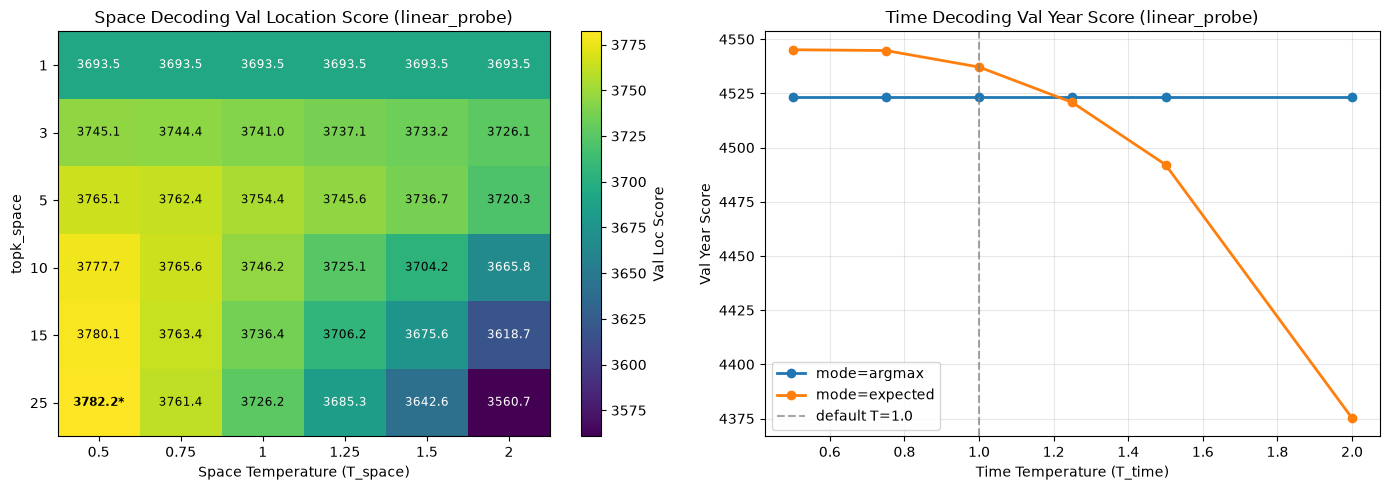

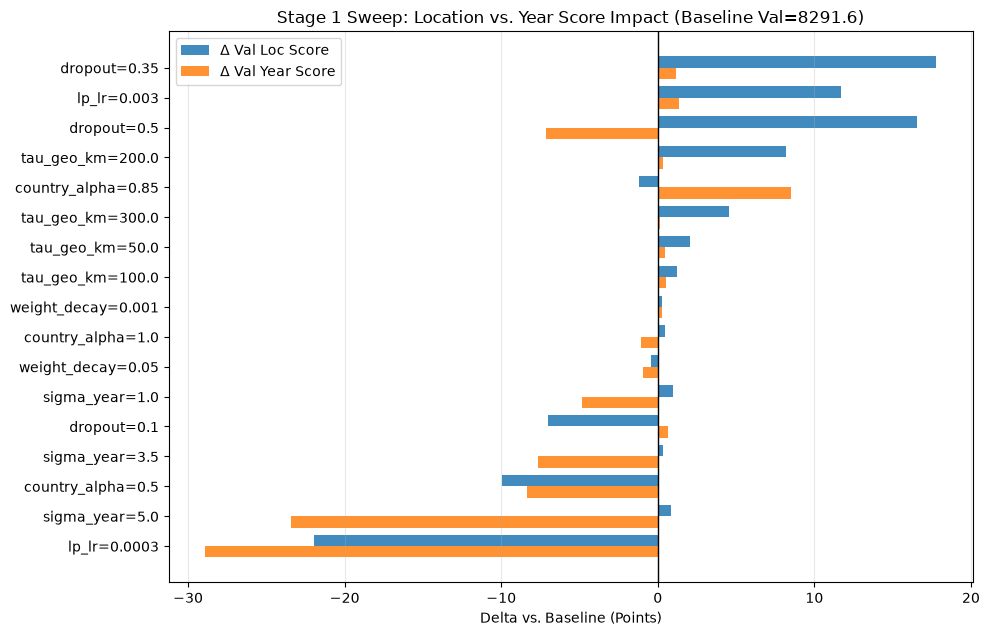

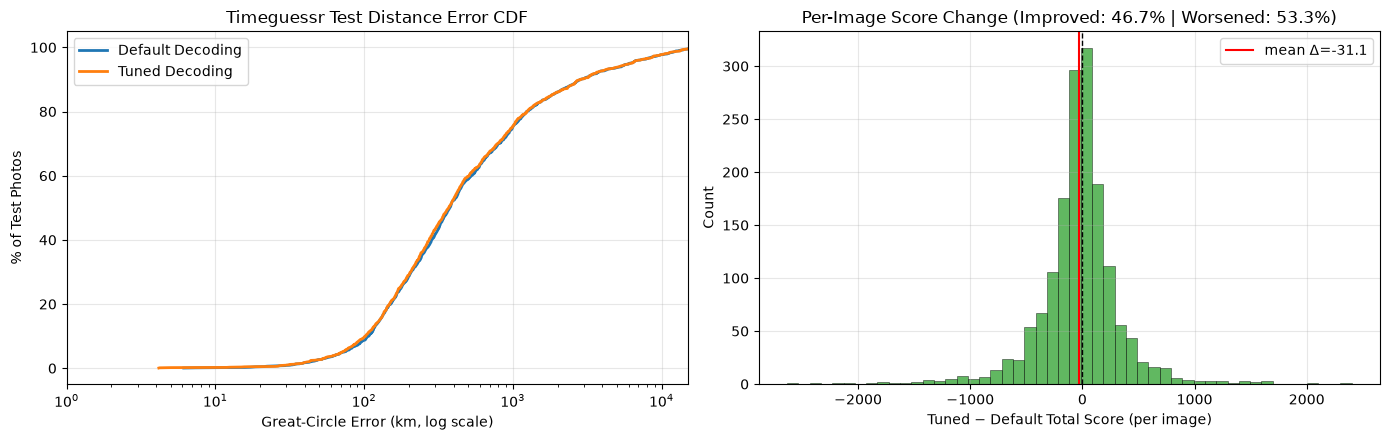

=== Tuned Predictions by Decade (Timeguessr Test) ===


,n,total_score,loc_score,year_score,median_km,year_mae
decade,,,,,,
1900,52,7494.12,3413.99,4080.13,492.26,7.10
1910,65,7254.50,3445.87,3808.63,341.70,6.64
1920,56,6926.75,3175.67,3751.08,454.64,6.86
1930,103,6894.53,3307.03,3587.51,493.35,8.23
1940,159,7365.05,3289.82,4075.22,491.78,5.57
1950,149,7460.23,3462.73,3997.50,329.77,5.92
1960,212,7949.50,3539.19,4410.31,359.88,3.91
1970,180,7730.65,3563.56,4167.10,328.16,5.01
1980,145,7731.92,3647.10,4084.82,335.56,5.53


In [10]:
decode_sweep_dir = PROJECT_ROOT / "outputs" / "sweeps"
target_name = DECODE_TARGET if "DECODE_TARGET" in globals() else (
    "finetune" if (decode_sweep_dir / "streetclip_finetune_space_decode_sweep.csv").exists() else "linear_probe"
)

# Load decoding sweep results (from memory or CSV)
s_df = space_sweep_df if "space_sweep_df" in globals() else pd.read_csv(
    decode_sweep_dir / f"streetclip_{target_name}_space_decode_sweep.csv"
)
t_df = time_sweep_df if "time_sweep_df" in globals() else pd.read_csv(
    decode_sweep_dir / f"streetclip_{target_name}_time_decode_sweep.csv"
)

# --- Figure 1: Post-Hoc Decoding Landscape ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (A) Space heatmap: topk_space x T_space -> val_loc_score
piv = s_df.pivot(index="topk_space", columns="T_space", values="val_loc_score").sort_index()
im = axes[0].imshow(piv.values, aspect="auto", cmap="viridis")
axes[0].set_xticks(range(len(piv.columns)))
axes[0].set_xticklabels([f"{c:g}" for c in piv.columns])
axes[0].set_yticks(range(len(piv.index)))
axes[0].set_yticklabels([str(r) for r in piv.index])
axes[0].set_xlabel("Space Temperature (T_space)")
axes[0].set_ylabel("topk_space")
axes[0].set_title(f"Space Decoding Val Location Score ({target_name})")
best_idx = np.unravel_index(np.argmax(piv.values), piv.values.shape)
vmin, vmax = piv.values.min(), piv.values.max()
for r in range(piv.shape[0]):
    for c in range(piv.shape[1]):
        val = piv.values[r, c]
        txt_color = "black" if (val - vmin) / max(vmax - vmin, 1e-6) > 0.6 else "white"
        marker = "*" if (r, c) == best_idx else ""
        axes[0].text(c, r, f"{val:.1f}{marker}", ha="center", va="center", color=txt_color, fontsize=8.5,
                     fontweight="bold" if marker else "normal")
fig.colorbar(im, ax=axes[0], label="Val Loc Score")

# (B) Time decoding curves: T_time vs val_year_score
for mode, grp in t_df.groupby("year_mode"):
    grp = grp.sort_values("T_time")
    axes[1].plot(grp["T_time"], grp["val_year_score"], marker="o", linewidth=2, label=f"mode={mode}")
axes[1].axvline(1.0, linestyle="--", color="gray", alpha=0.7, label="default T=1.0")
axes[1].set_title(f"Time Decoding Val Year Score ({target_name})")
axes[1].set_xlabel("Time Temperature (T_time)")
axes[1].set_ylabel("Val Year Score")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# --- Figure 2: Stage 1 Hyperparameter Deltas (if Section 4 was run) ---
stage1_csv = PROJECT_ROOT / "outputs" / "sweeps" / "streetclip_stage1" / "sweep_results.csv"
if "sweep_df" in globals() or stage1_csv.exists():
    s1_df = sweep_df.copy() if "sweep_df" in globals() else pd.read_csv(stage1_csv)
    base = s1_df[s1_df["swept_param"] == "baseline"].iloc[0]
    pert = s1_df[s1_df["swept_param"] != "baseline"].copy()
    pert["d_total"] = pert["val_total_score"] - base["val_total_score"]
    pert["d_loc"] = pert["val_loc_score"] - base["val_loc_score"]
    pert["d_year"] = pert["val_year_score"] - base["val_year_score"]
    pert = pert.sort_values("d_total")

    y = np.arange(len(pert))
    h = 0.38
    fig, ax = plt.subplots(figsize=(10, max(5, 0.38 * len(pert))))
    ax.barh(y + h / 2, pert["d_loc"], height=h, label="Δ Val Loc Score", color="tab:blue", alpha=0.85)
    ax.barh(y - h / 2, pert["d_year"], height=h, label="Δ Val Year Score", color="tab:orange", alpha=0.85)
    ax.axvline(0.0, color="black", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(pert["run_name"])
    ax.set_xlabel("Delta vs. Baseline (Points)")
    ax.set_title(f"Stage 1 Sweep: Location vs. Year Score Impact (Baseline Val={base['val_total_score']:.1f})")
    ax.legend()
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Note: Run Section 4 first to generate Stage 1 sweep delta plots.")

# --- Figure 3 & Table: Default vs. Tuned Decoding Analysis on Timeguessr Test ---
if "test_t_logits" in globals() and "test_s_logits" in globals():
    best_s = s_df.sort_values("val_loc_score", ascending=False).iloc[0]
    best_t = t_df.sort_values("val_year_score", ascending=False).iloc[0]

    def _get_pred_df(t_logits, s_logits, topk, t_s, t_t, mode):
        dec = decode_predictions(t_logits / t_t, s_logits / t_s, cells_df, topk_space=topk)
        yr = dec["pred_year"] if mode == "expected" else dec["pred_year_argmax"]
        _, pdf = evaluate_predictions(
            splits["test_timeguessr"], dec["pred_lat_topk"], dec["pred_lon_topk"], yr,
            pred_tile_id=dec["pred_tile_id"], cells_df=cells_df,
        )
        return pdf

    def_pdf = _get_pred_df(test_t_logits, test_s_logits, 5, 1.0, 1.0, "expected")
    tun_pdf = _get_pred_df(
        test_t_logits, test_s_logits,
        int(best_s["topk_space"]), float(best_s["T_space"]), float(best_t["T_time"]), str(best_t["year_mode"]),
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    # (A) Distance Error CDF
    for label, pdf in [("Default Decoding", def_pdf), ("Tuned Decoding", tun_pdf)]:
        dists = np.sort(pdf["dist_km"].to_numpy())
        cdf = np.arange(1, len(dists) + 1) / len(dists) * 100.0
        axes[0].plot(dists, cdf, linewidth=2, label=label)
    axes[0].set_xscale("log")
    axes[0].set_xlim(1, 15000)
    axes[0].set_xlabel("Great-Circle Error (km, log scale)")
    axes[0].set_ylabel("% of Test Photos")
    axes[0].set_title("Timeguessr Test Distance Error CDF")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # (B) Per-sample total score change distribution
    delta = tun_pdf["total_score"].to_numpy() - def_pdf["total_score"].to_numpy()
    improved_pct = (delta > 0).mean() * 100.0
    worsened_pct = (delta < 0).mean() * 100.0
    axes[1].hist(delta, bins=50, color="tab:green", alpha=0.75, edgecolor="black", linewidth=0.4)
    axes[1].axvline(0.0, color="black", linestyle="--", linewidth=1)
    axes[1].axvline(delta.mean(), color="red", linewidth=1.5, label=f"mean Δ={delta.mean():+.1f}")
    axes[1].set_xlabel("Tuned − Default Total Score (per image)")
    axes[1].set_ylabel("Count")
    axes[1].set_title(f"Per-Image Score Change (Improved: {improved_pct:.1f}% | Worsened: {worsened_pct:.1f}%)")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Decade breakdown for tuned predictions
    tun_pdf["decade"] = (tun_pdf["true_year"] // 10) * 10
    decade_summary = tun_pdf.groupby("decade").agg(
        n=("total_score", "size"),
        total_score=("total_score", "mean"),
        loc_score=("loc_score", "mean"),
        year_score=("year_score", "mean"),
        median_km=("dist_km", "median"),
        year_mae=("year_err", "mean"),
    ).round(2)
    print("=== Tuned Predictions by Decade (Timeguessr Test) ===")
    display(decade_summary)
else:
    print("Run Section 5 first to populate test logits for per-image & decade error analysis.")